In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
# from tqdm.notebook import tqdm

from parallel_pandas import ParallelPandas
ParallelPandas.initialize(n_cpu=12)

from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer, QuantileTransformer, FunctionTransformer
from sklearn.cluster import BisectingKMeans
from sklearn.manifold import TSNE, trustworthiness
import umap
import hdbscan

import pickle
import os
import glob
import json

import warnings 
from IPython.display import display, HTML
warnings.filterwarnings("ignore")
plt.rcParams["patch.force_edgecolor"] = True

import veriwild_clustering as vwc

In [2]:
import kagglehub
dataset_path = kagglehub.dataset_download("markhomeless/intellivision-case")

In [3]:
# Список изображений
imglist = pd.read_csv(os.path.join(dataset_path, "IntelliVision_case", "images_paths.csv"))['paths']
imglist.head()

0    veriwild\1\00001\000001.jpg
1    veriwild\1\00001\000002.jpg
2    veriwild\1\00001\000003.jpg
3    veriwild\1\00001\000004.jpg
4    veriwild\1\00001\000005.jpg
Name: paths, dtype: str

In [4]:
# Папка с изображениями
imgpath = os.path.join(dataset_path, "IntelliVision_case", "raw_data")

# Размер поля для вывода 10 изображений в 2 ряда по 5 штук
FIGSIZE_IMG2X5 = (10, 5)

In [5]:
# Чтение очищенного датасета
with open(os.path.join('temp', 'efficientnet_cleaned.pickle'), 'rb') as pkl_file:
    efficientnet_cleaned = pickle.load(pkl_file)
    print(f'{"efficientnet_cleaned":<22}', efficientnet_cleaned.shape)

efficientnet_cleaned   (416314, 2560)


# 3. Кластеризация

## 3.1. efficientnet-b7, папйплайн по столбцам

### 2 кластера KMeans

In [6]:
%%time

efficientnet_pkmc = vwc.PipeKMeansCluster(
    pca_n_components=371, 
    n_clusters=2, 
    distorsion='QuantileTransform'
)
efficientnet_labels_kmeans = efficientnet_pkmc.fit_predict(efficientnet_cleaned)

CPU times: total: 10min 45s
Wall time: 4min 29s


In [7]:
# Распределение кластеров
pd.concat([
    pd.Series(efficientnet_labels_kmeans).value_counts(normalize=True),
    pd.Series(efficientnet_labels_kmeans).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
0,0.223709,93133
1,0.776291,323181


In [8]:
# 10 ближайших соседей к центроидам каждого кластера

_, efficientnet_indices_kmeans = vwc.get_kmeans_centroid_samples(
    data=efficientnet_pkmc.X_pca,
    cluster_centers=efficientnet_pkmc.kmeans.cluster_centers_,
    n_samples=15
)

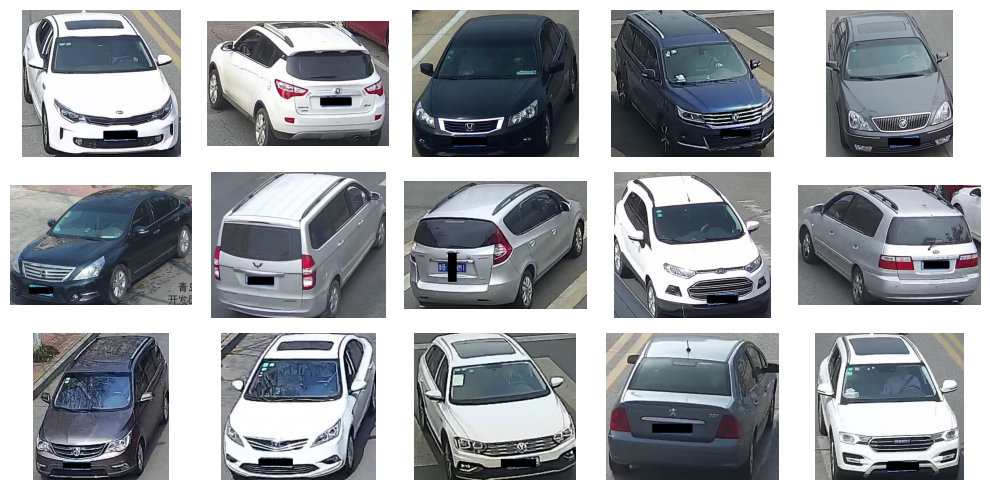

In [9]:
# Самые типичные представители класса 0 в efficientnet-b7
vwc.draw_images(
    imgpath,
    imglist[efficientnet_indices_kmeans[0]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

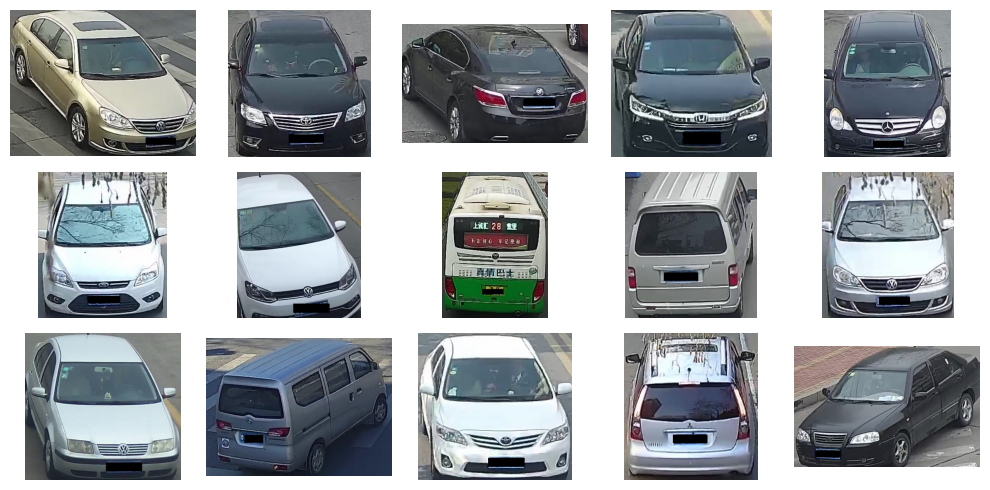

In [10]:
# Самые типичные представители класса 1 в efficientnet-b7
vwc.draw_images(
    imgpath,
    imglist[efficientnet_indices_kmeans[1]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

Размерность всё ещё слишком высокая, трансформированный набор данных содержит 375 столбцов. Статистика Хопкинса (H=0.715) уверенно указывает на наличие групп в данных. Лучшее разделение предполагает всего 2 кластера, причем с очень высокой стабильностью (mean=0.936, std=0.032). Визуальный просмотр изображений — типичных представителей каждого кластера (расположены наиболее близко к центроидам) не дает никаких предположений, по каким признакам произошла группировка. KMeans нацелен на выпуклые, сферические кластеры. Однако похоже, что данные здесь имеют совершенно другую структуру, и KMeans нашел лишь устойчивое макро-разделение, не заметив более тонкие внутренние «сгустки». Кроме того, для модели классификации EfficientNet выглядит сомнительным наличие всего лишь 2 кластеров. Такое разделение требует подтверждения.

In [11]:
# Быстрый тест на иерархичность:
# BisectingKMeans проверяет, делятся ли 2 макро-кластера на подкластеры

X_trans = efficientnet_pkmc.X_pca

df_stab = []
for k in [2, 3, 4, 5, 6, 7, 8]:
    bkmeans = BisectingKMeans(n_clusters=k, random_state=42)
    labels = bkmeans.fit_predict(X_trans)
    # Стабильность для каждого K
    stability = vwc.cluster_stability(X_trans, n_clusters=k)
    print(f"Bisecting K={k}: Stability mean={stability['stability_mean']:.3f}, std={stability['stability_std']:.3f}")
    df_stab.append({'k': k, 'mean':stability['stability_mean'], 'std': stability['stability_std']})

df_stab = pd.DataFrame(df_stab)

Bisecting K=2: Stability mean=0.934, std=0.031
Bisecting K=3: Stability mean=0.578, std=0.208
Bisecting K=4: Stability mean=0.435, std=0.169
Bisecting K=5: Stability mean=0.425, std=0.073
Bisecting K=6: Stability mean=0.459, std=0.102
Bisecting K=7: Stability mean=0.382, std=0.097
Bisecting K=8: Stability mean=0.373, std=0.062


### UMAP/HDBSCAN

Дополнительная проверка на иерархичность не смогла выявить локальные структуры в данных. Для алгоритмов семейства KMeans самая высокая стабильность по-прежнему наблюдается при разделении на 2 кластера. Нужно переходить к принципиально другим алгоритмам кластеризации либо менять геометрию пространства. В задачах подобного рода хорошей практикой является уменьшение размерности с помощью UMAP с последующей кластеризацией алгоритмом HDBSCAN. Индексы Калински-Харабаса и Дэвиса-Болдина здесь не используются, так как будут зависеть от параметров UMAP. Для подбора новой размерности используется метрика сохранения окрестности (trustworthiness), показывающая, насколько близкое соседство в исходном пространстве сохраняется в сжатом. Оптимальной можно считать такую размерность, где trustworthiness выходит на плато, а также минимизируется доля неразмеченного шума, которую возвращает HDBSCAN. Для борьбы с шумом подобираются параметры cluster_selection_epsilon и min_samples. Первый задает пороговое значение расстояния, при котором мелкие кластеры объединяются в более крупные. Второй — минимальное количество соседей, которые делают точку «основной». Кроме того, ускоренную калибровку параметров можно провести не на всех данных, а на его подмножестве, например, 25%. 

In [11]:
# Тот же датасет с уменьшенной размерностью 371 после PCA
X_trans = efficientnet_pkmc.X_pca

# Подвыборка 25% для калибровки (100 тыс. автомобилей)
calibration_factor = 0.25

In [12]:
umap_n_neighbors = 50 # Увеличено для макро-кластеров

In [14]:
%%time 

umap_dims = [3, 5, 8, 10, 15, 20]
eps_values = [0.0, 0.1, 0.3, 0.5, 0.8, 1.0]
min_samples_values = [2, 5, 10, 25, 50, 100, 250]

df_umap = vwc.umap_hdbscan_measure(
    X_trans,
    sample_frac=calibration_factor,
    umap_n_components=umap_dims,
    umap_n_neighbors=umap_n_neighbors,  
    umap_metric='euclidean',
    cluster_selection_epsilon=eps_values,
    min_samples=min_samples_values,
    ram_factor=0.7,
    n_jobs=10
)

Используется выборка: 416314 -> 104078 строк (25.0%)
Для trustworthiness выборка уменьшена: 104078 -> 65105 строк (62.6%)


umap_dim: 100%|██████████| 6/6 [1:48:47<00:00, 1087.90s/it]


CPU times: total: 1h 40min 41s
Wall time: 1h 48min 48s


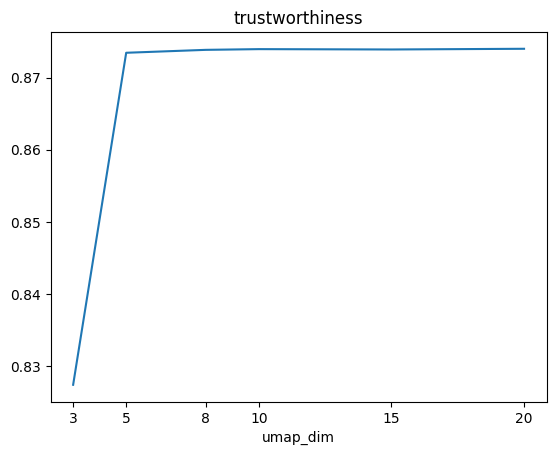

In [15]:
# trustworthiness выходит на плато начиная с umap_dim=5
g_umap_dim = df_umap.groupby('umap_dim', sort=True)['trustworthiness'].first()
ax = g_umap_dim.plot()
ax.set_xticks(g_umap_dim.index.to_list())
ax.set_title('trustworthiness');

In [16]:
# Минимальная доля шума наблюдается для eps>=0.5, min_samples=100, umap_dim=8
s_umap_dim = df_umap[df_umap['umap_dim']>=5]
noise_pct_rank = s_umap_dim.groupby(['eps', 'min_samples'])['noise_pct'].rank(method='dense', ascending=True)
s_umap_dim = s_umap_dim[noise_pct_rank==1]
noise_pct_rank = s_umap_dim['noise_pct'].rank(method='dense', ascending=True)

s_umap_dim[noise_pct_rank==1]

,eps,min_samples,umap_dim,trustworthiness,clusters_found,noise_pct,min_cluster_pct,min_cluster_cnt
26,0.0,50,8,0.873839,2,0.147149,0.046179,4099
68,0.1,50,8,0.873839,2,0.147149,0.046179,4099
110,0.3,50,8,0.873839,2,0.147149,0.046179,4099
152,0.5,50,8,0.873839,2,0.147149,0.046179,4099
194,0.8,50,8,0.873839,2,0.147149,0.046179,4099
236,1.0,50,8,0.873839,2,0.147149,0.046179,4099


Показатель trustworthiness выходит на плато около 0.87, начиная с размерности UMAP, равной 5. Геометрия соседства хорошо сохраняется. Разбиение получается всего на 2 кластера, причем неравномерное — на долю меньшего приходится около 5% точек. Если же не пытаться минимизировать шум, то возможны варианты с 7-8 кластерами, но при этом доля шума становится огромной — до 70%. 

Для воспроизведения результатов кластеризации, полученных при калибровке параметров, на полном наборе данных можно пойти двумя путями. Первый — масштабирование параметров в соответствии с их геометрическим смыслом. Этот подход требует чуть больше вычислений, но работает аккуратнее. Второй — сделать инференс с помощью предобученных на подвыборке моделей. Далее будет применен первый способ, и на это есть причина.

В UMAP метод fit_transform двигает все точки одновременно силами притяжения и отталкивания. Новые точки, переданные методу transform, будут проецироваться независимо через стохастический градиентный спуск (SGD). Они будут притягиваться к соседям из обучающей выборки, но не отталкиваться от других новых точек. Параметр min_dist = 0.0 сжимает точки из обучающей выборки в максимально плотные стуктуры. Из-за неизбежной погрешности оптимизации новые точки проецируются с небольшим «размытием» и падают чуть в сторону от этих структур. Другими словами, топология пространства будет меняться менее эластично. Там, где точки должны располагаться более-менее равномерно, начнут образовываться полости с низкой плотностью. 

Когда HDBSCAN обучается на выборке, он строит дерево взаимной достижимости (mutual reachability tree) с расстояниями между точек. При инференсе через approximate_predict каждая новая точка оценивается изолированно по отношению к «разреженной» сетке из исходных 25% точек.
Если такая точка попадет чуть в сторону от опорных ядер в обучающей выборке, расстояние взаимной достижимости превысит порог устойчивости кластера. Для HDBSCAN этого достаточно, чтобы счесть точку выбросом. Таким образом, большинство новых точек может превратиться в шум. Для компенсации этого эффекта можно немного повысить min_dist, например, до 0.05, но это не гарантирует желаемого результата.

In [39]:
%%time

import umap
import hdbscan

umap_n_neighbors = 50

umap_dim = 8
eps_value = 0.5
min_samples_value = 50

# Коэффициент увеличения объема выборки
scale = 1.0 / calibration_factor

# UMAP: n_neighbors масштабируется через логарифм
n_neighbors_full = int(umap_n_neighbors * (1.0 + np.log2(scale)))

# 2. HDBSCAN: min_samples задает радиус ядерных точек (core distance). 
# Если плотность в выборке вырастает, то радиус должен уменьшиться.
min_samples_full = int(min_samples_value * (1.0 + np.log2(scale)))

# 3. HDBSCAN: epsilon сжимается обратно пропорционально линейной плотности в d-мерном пространстве UMAP
eps_full = eps_value * (calibration_factor ** (1.0 / umap_dim))

# 4. HDBSCAN: min_cluster_size масштабируется пропорционально квадратному корню. 
# Это компромиссный вариант, чтобы сохранить пропорции кластеров и не задавить мелкие и средние кластеры.
min_cluster_size_full = max(1, int(
    (int(X_trans.shape[0] * calibration_factor * 0.02)) * np.sqrt(scale)
))

print(f'{scale=}, n_neighbors={n_neighbors_full}, min_samples={min_samples_full}, cluster_selection_epsilon={eps_full:.2f}, min_cluster_size={min_cluster_size_full}')

reducer = umap.UMAP(
    n_components=umap_dim, 
    n_neighbors=n_neighbors_full,    
    min_dist=0.0,       
    metric='euclidean', 
    n_jobs=10,
    random_state=42
)
X_umap = reducer.fit_transform(X_trans)
hdb = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size_full, 
    min_samples=min_samples_full,     
    cluster_selection_epsilon=eps_full,
    cluster_selection_method="eom",
    core_dist_n_jobs=12,
    prediction_data=True
)
efficientnet_labels_hdbscan = hdb.fit_predict(X_umap)

scale=4.0, n_neighbors=150, min_samples=150, cluster_selection_epsilon=0.42, min_cluster_size=4162
CPU times: total: 1h 3min 15s
Wall time: 34min 2s


In [40]:
# Распределение кластеров
pd.concat([
    pd.Series(efficientnet_labels_hdbscan).value_counts(normalize=True),
    pd.Series(efficientnet_labels_hdbscan).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
-1,0.350505,145920
0,0.024378,10149
1,0.625117,260245


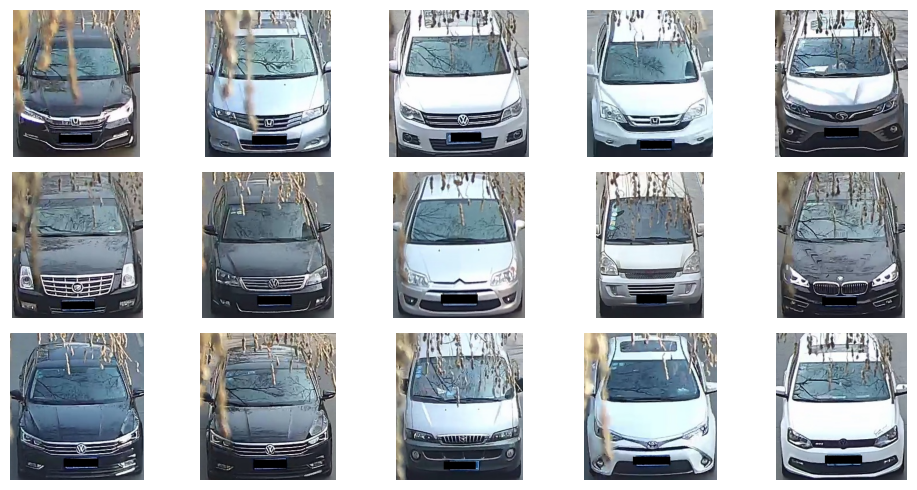

In [41]:
# 15 самых типичных представителей класса 0 в efficientnet-b7

efficientnet_0_indices = vwc.get_hdbscan_best_cluster_samples(hdb, 0, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_0_indices].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

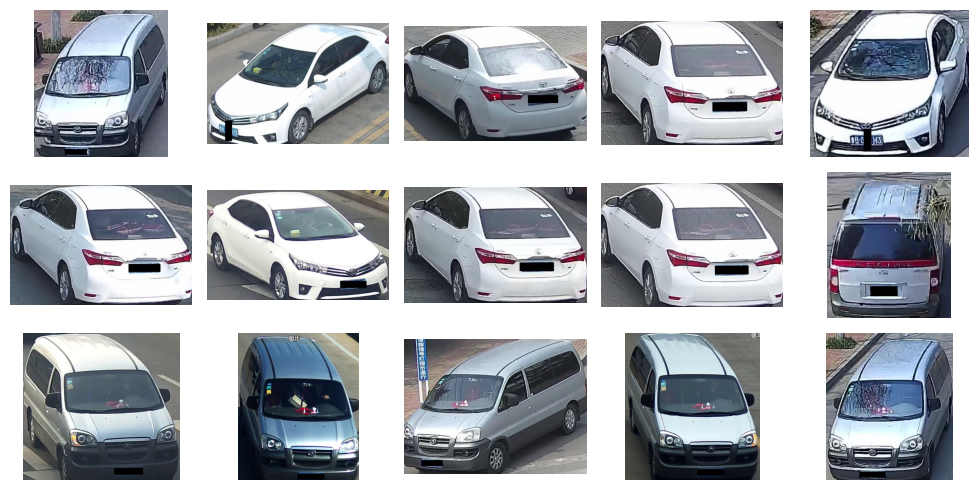

In [42]:
# 15 самых типичных представителей класса 1 в efficientnet-b7

efficientnet_1_indices = vwc.get_hdbscan_best_cluster_samples(hdb, 1, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_1_indices].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

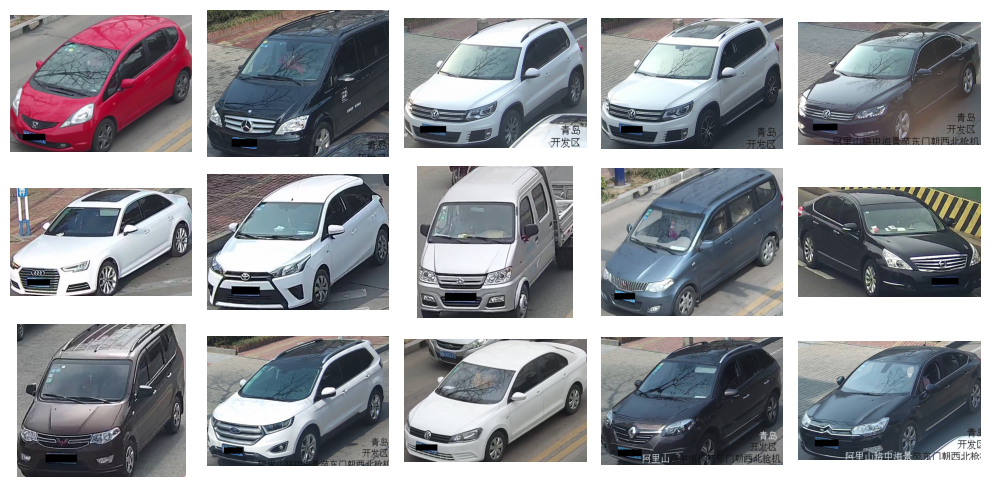

In [43]:
# 10 самых далеких выбросов в efficientnet-b7
efficientnet_hdbscan_outliers = vwc.get_hdbscan_outliers_samples(hdb, 15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_hdbscan_outliers].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

In [33]:
%%time

# t-SNE для визуализации

from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42, n_jobs=12)
X_tsne = tsne.fit_transform(X_umap)

CPU times: total: 3h 4min 53s
Wall time: 21min 15s


In [44]:
efficientnet_visual2_tsne = pd.DataFrame(
    np.hstack([
        X_tsne, 
        efficientnet_labels_hdbscan.reshape(-1, 1),
        efficientnet_labels_kmeans.reshape(-1, 1)
    ]), 
    columns=['x', 'y', 'cluster_hdbscan', 'cluster_kmeans']
)
efficientnet_visual2_tsne['cluster_hdbscan'] = efficientnet_visual2_tsne['cluster_hdbscan'].astype(np.int8)
efficientnet_visual2_tsne['cluster_kmeans'] = efficientnet_visual2_tsne['cluster_kmeans'].astype(np.int8)

In [45]:
# Перевод меток KMeans в систему координат HDBSCAN
mapping = vwc.match_labels(
    efficientnet_visual2_tsne['cluster_hdbscan'].to_numpy(),
    efficientnet_visual2_tsne['cluster_kmeans'].to_numpy()
)
efficientnet_visual2_tsne['cluster_kmeans_aligned'] = efficientnet_visual2_tsne['cluster_kmeans'].map(mapping)

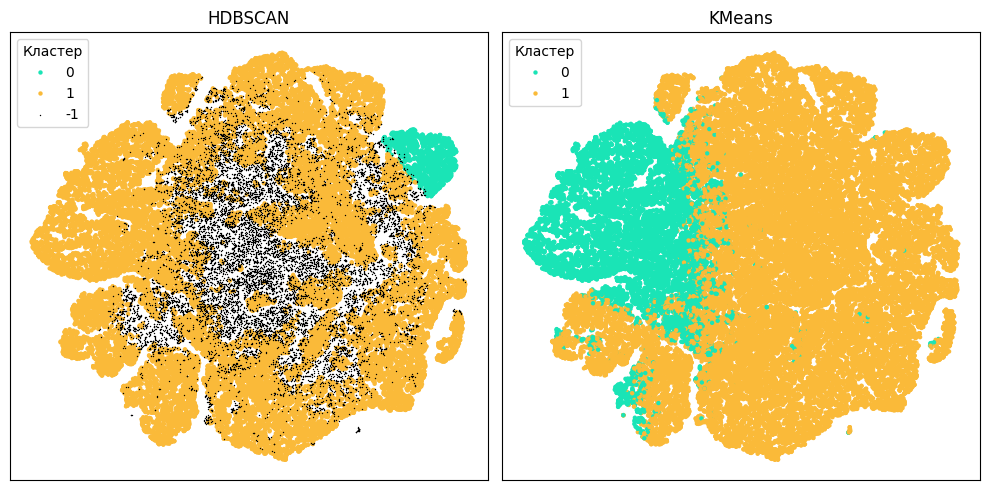

In [46]:
vwc.show_2d_spaces(
    efficientnet_visual2_tsne, 
    'cluster_hdbscan', 'cluster_kmeans_aligned',
    frac=0.1, palette='turbo'
)

Результаты кластеризации HDBSCAN следует признать неудовлетворительными. Во-первых, 35% шума это слишком много. Во-вторых, всего два кластера совершенно не отражают многообразие автомобилей. В-третьих, меньший кластер составляет всего 2.5% данных и, скорее всего, содержит изображения с ветками деревьев. Алгоритмы KMeans и HDBSCAN поделили данные принципиально разными способами.

In [ ]:
# Сохранение меток
# efficientnet_visual2_tsne[['cluster_hdbscan', 'cluster_kmeans_aligned']].to_csv(
#     os.path.join('temp', 'efficientnet_colspipeline_labels.csv'), 
#     index=False
# )

## 3.2. efficientnet-b7, папйплайн по строкам

### 2 кластера KMeans

In [6]:
%%time

efficientnet_pkmc_l2 = vwc.PipeKMeansClusterL2(
    pca_n_components=373, 
    n_clusters=2
)
efficientnet_labels_l2_kmeans = efficientnet_pkmc_l2.fit_predict(efficientnet_cleaned)

CPU times: total: 7min 31s
Wall time: 46.9 s


In [7]:
# Распределение кластеров
pd.concat([
    pd.Series(efficientnet_labels_l2_kmeans).value_counts(normalize=True),
    pd.Series(efficientnet_labels_l2_kmeans).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
0,0.365875,152319
1,0.634125,263995


In [8]:
# 15 ближайших соседей к центроидам каждого кластера

_, efficientnet_indices_kmeans_l2 = vwc.get_kmeans_centroid_samples(
    data=efficientnet_pkmc_l2.X_pca,
    cluster_centers=efficientnet_pkmc_l2.kmeans.cluster_centers_,
    n_samples=15
)

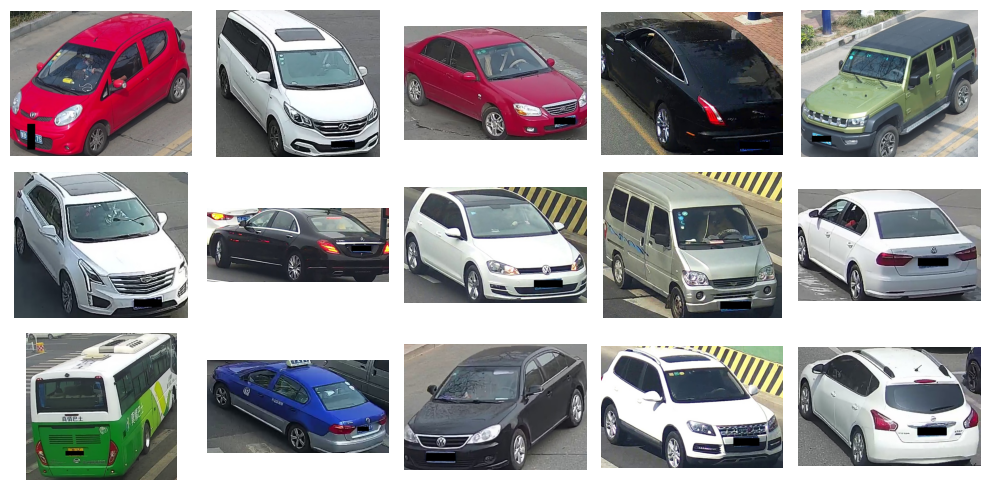

In [9]:
# Самые типичные представители класса 0 в efficientnet-b7
vwc.draw_images(
    imgpath,
    imglist[efficientnet_indices_kmeans_l2[0]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

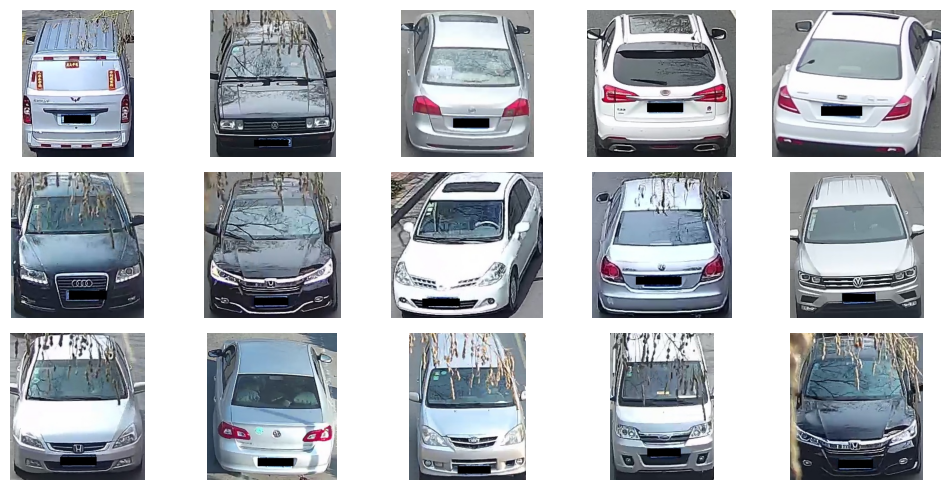

In [10]:
# Самые типичные представители класса 1 в efficientnet-b7
vwc.draw_images(
    imgpath,
    imglist[efficientnet_indices_kmeans_l2[1]].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

In [11]:
# Быстрый тест на иерархичность:
# BisectingKMeans проверяет, делятся ли 2 макро-кластера на подкластеры

X_trans = efficientnet_pkmc_l2.X_pca

df_stab = []
for k in [2, 3, 4, 5, 6, 7, 8]:
    bkmeans = BisectingKMeans(n_clusters=k, random_state=42)
    labels = bkmeans.fit_predict(X_trans)
    # Стабильность для каждого K
    stability = vwc.cluster_stability(X_trans, n_clusters=k)
    print(f"Bisecting K={k}: Stability mean={stability['stability_mean']:.3f}, std={stability['stability_std']:.3f}")
    df_stab.append({'k': k, 'mean':stability['stability_mean'], 'std': stability['stability_std']})

df_stab = pd.DataFrame(df_stab)

Bisecting K=2: Stability mean=0.942, std=0.032
Bisecting K=3: Stability mean=0.409, std=0.245
Bisecting K=4: Stability mean=0.636, std=0.079
Bisecting K=5: Stability mean=0.491, std=0.017
Bisecting K=6: Stability mean=0.413, std=0.059
Bisecting K=7: Stability mean=0.406, std=0.032
Bisecting K=8: Stability mean=0.478, std=0.028


Похоже, что алгоритм KMeans сгруппировал изображения по ракурсу съемки автомобилей. Для кластера 0 характерен вид немного сбоку, а для кластера 1 — вид с переднего или заднего торца. Тест на иерархичность показывает потенциально интересное решение с 4 кластерами.

### UMAP/HDBSCAN на 2 кластера

In [12]:
# Тот же датасет с уменьшенной размерностью 373 после PCA
X_trans = efficientnet_pkmc_l2.X_pca

# Подвыборка 25% для калибровки (100 тыс. автомобилей)
calibration_factor = 0.25

In [13]:
umap_n_neighbors = 50 # Увеличено для макро-кластеров

In [14]:
%%time 

umap_dims = [3, 5, 8, 10, 15, 20]
eps_values = [0.0, 0.1, 0.3, 0.5, 0.8, 1.0]
min_samples_values = [2, 5, 10, 25, 50, 100, 250, 500]

df_umap = vwc.umap_hdbscan_measure(
    X_trans,
    sample_frac=calibration_factor,
    umap_n_components=umap_dims,
    umap_n_neighbors=umap_n_neighbors,  
    umap_metric='cosine',
    cluster_selection_epsilon=eps_values,
    min_samples=min_samples_values,
    ram_factor=0.7,
    n_jobs=10
)

Используется выборка: 416314 -> 104078 строк (25.0%)
Для trustworthiness выборка уменьшена: 104078 -> 67944 строк (65.3%)


umap_dim: 100%|██████████| 6/6 [1:51:18<00:00, 1113.00s/it]


CPU times: total: 1h 44min 22s
Wall time: 1h 51min 18s


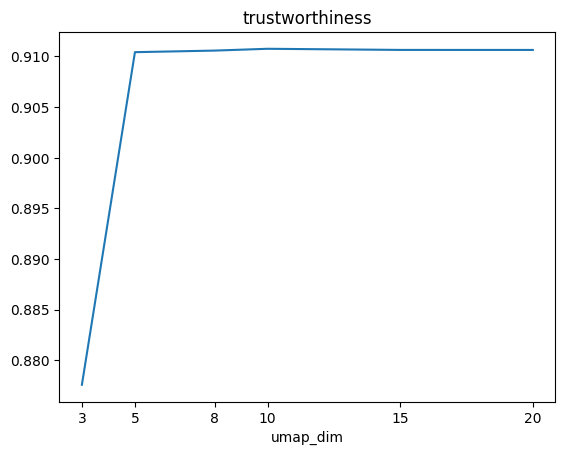

In [15]:
# trustworthiness выходит на плато начиная с umap_dim=5
g_umap_dim = df_umap.groupby('umap_dim', sort=True)['trustworthiness'].first()
ax = g_umap_dim.plot()
ax.set_xticks(g_umap_dim.index.to_list())
ax.set_title('trustworthiness');

In [16]:
# Минимальная доля шума наблюдается для eps>=0.5, min_samples=100, umap_dim=15
s_umap_dim = df_umap[df_umap['umap_dim']>=5]
noise_pct_rank = s_umap_dim.groupby(['eps', 'min_samples'])['noise_pct'].rank(method='dense', ascending=True)
s_umap_dim = s_umap_dim[noise_pct_rank==1]
noise_pct_rank = s_umap_dim['noise_pct'].rank(method='dense', ascending=True)

s_umap_dim[noise_pct_rank==1]

,eps,min_samples,umap_dim,trustworthiness,clusters_found,noise_pct,min_cluster_pct,min_cluster_cnt
25,0.0,50,5,0.910425,2,0.045533,0.343873,34160
73,0.1,50,5,0.910425,2,0.045533,0.343873,34160
121,0.3,50,5,0.910425,2,0.045533,0.343873,34160
169,0.5,50,5,0.910425,2,0.045533,0.343873,34160
217,0.8,50,5,0.910425,2,0.045533,0.343873,34160
265,1.0,50,5,0.910425,2,0.045533,0.343873,34160


Показатель trustworthiness выходит на плато около 0.91, начиная с размерности UMAP, равной 5. Геометрия соседства отлично сохраняется. Доля шума мала. Разбиение получается всего на 2 кластера, на долю меньшего приходится 34% точек. При малых значениях cluster_selection_epsilon модель склонна к созданию нескольких очень маленьких кластеров и высокой доле шума. Подход к предварительной обработке с помощью нормализации по строкам оказался более предпочтительным. 

In [ ]:
%%time

import umap
import hdbscan

umap_n_neighbors = 50

umap_dim = 5
eps_value = 0.3
min_samples_value = 50 

# Коэффициент увеличения объема выборки
scale = 1.0 / calibration_factor

# UMAP: n_neighbors масштабируется через логарифм
n_neighbors_full = int(umap_n_neighbors * (1.0 + np.log2(scale)))

# 2. HDBSCAN: min_samples задает радиус ядерных точек (core distance). 
# Если плотность в выборке вырастает, то радиус должен уменьшиться.
min_samples_full = int(min_samples_value * (1.0 + np.log2(scale)))

# 3. HDBSCAN: epsilon сжимается обратно пропорционально линейной плотности в d-мерном пространстве UMAP
eps_full = eps_value * (calibration_factor ** (1.0 / umap_dim))

# 4. HDBSCAN: min_cluster_size необходимо сохранить в размере 2% данных, так как модель склонна создавать много маленьких кластеров
min_cluster_size_full = max(1, int(X_trans.shape[0] * 0.02)) 

print(f'{scale=}, n_neighbors={n_neighbors_full}, min_samples={min_samples_full}, cluster_selection_epsilon={eps_full:.2f}, min_cluster_size={min_cluster_size_full}')

reducer = umap.UMAP(
    n_components=umap_dim, 
    n_neighbors=n_neighbors_full,    
    min_dist=0.0,       
    metric='cosine', 
    n_jobs=10,
    random_state=42
)
X_umap = reducer.fit_transform(X_trans)
hdb = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size_full, 
    min_samples=min_samples_full,     
    cluster_selection_epsilon=eps_full,
    cluster_selection_method="eom",
    core_dist_n_jobs=12,
    prediction_data=True
)
efficientnet_labels_l2_hdbscan = hdb.fit_predict(X_umap)

scale=4.0, n_neighbors=150, min_samples=150, cluster_selection_epsilon=0.23, min_cluster_size=8326
CPU times: total: 1h 2min 3s
Wall time: 31min 37s


In [63]:
# Распределение кластеров
pd.concat([
    pd.Series(efficientnet_labels_l2_hdbscan).value_counts(normalize=True),
    pd.Series(efficientnet_labels_l2_hdbscan).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
-1,0.172826,71950
0,0.291854,121503
1,0.535319,222861


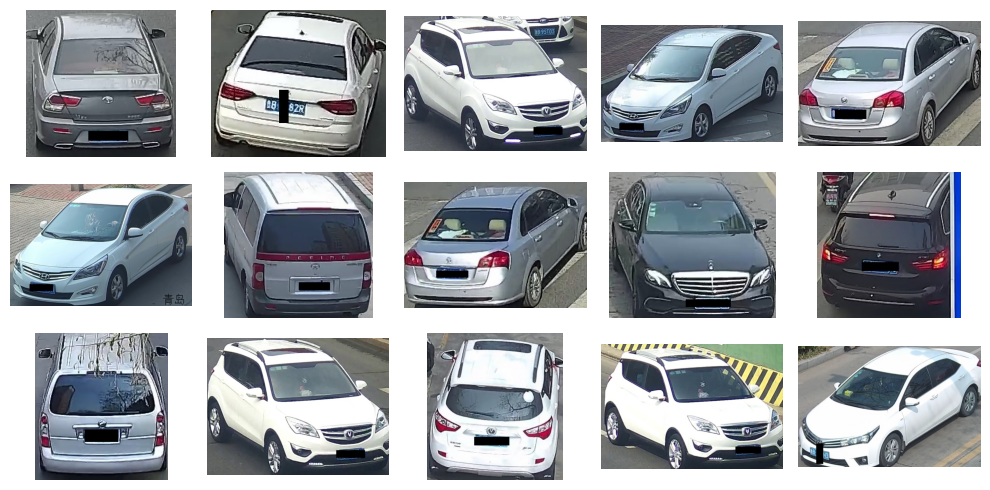

In [64]:
# 15 самых типичных представителей класса 0 в efficientnet-b7

efficientnet_0_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb, 0, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_0_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

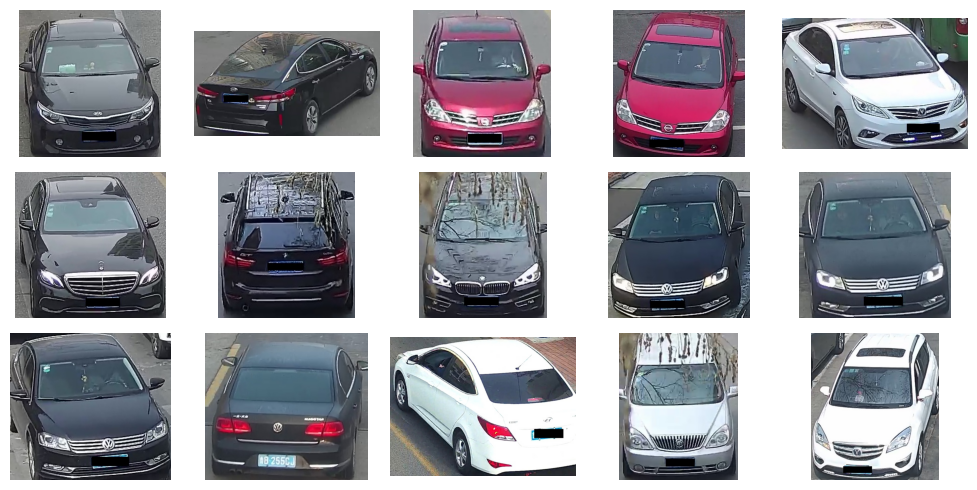

In [65]:
# 15 самых типичных представителей класса 1 в efficientnet-b7

efficientnet_1_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb, 1, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_1_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

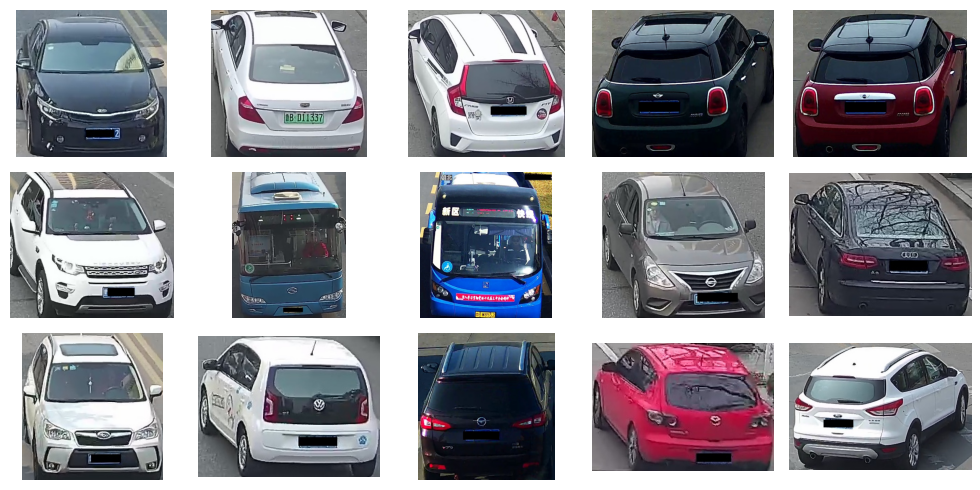

In [ ]:
# 15 самых далеких выбросов в efficientnet-b7
efficientnet_hdbscan_outliers_l2 = vwc.get_hdbscan_outliers_samples(hdb, 15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_hdbscan_outliers_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

In [68]:
%%time

# t-SNE для визуализации

from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42, n_jobs=12)
X_tsne = tsne.fit_transform(X_umap)

CPU times: total: 2h 45min 13s
Wall time: 19min 12s


In [69]:
efficientnet_visual2_tsne_l2 = pd.DataFrame(
    np.hstack([
        X_tsne, 
        efficientnet_labels_l2_hdbscan.reshape(-1, 1),
        efficientnet_labels_l2_kmeans.reshape(-1, 1)
    ]), 
    columns=['x', 'y', 'cluster_hdbscan', 'cluster_kmeans']
)
efficientnet_visual2_tsne_l2['cluster_hdbscan'] = efficientnet_visual2_tsne_l2['cluster_hdbscan'].astype(np.int8)
efficientnet_visual2_tsne_l2['cluster_kmeans'] = efficientnet_visual2_tsne_l2['cluster_kmeans'].astype(np.int8)

In [71]:
# Перевод меток KMeans в систему координат HDBSCAN
mapping = vwc.match_labels(
    efficientnet_visual2_tsne_l2['cluster_hdbscan'].to_numpy(),
    efficientnet_visual2_tsne_l2['cluster_kmeans'].to_numpy()
)
efficientnet_visual2_tsne_l2['cluster_kmeans_aligned'] = efficientnet_visual2_tsne_l2['cluster_kmeans'].map(mapping)

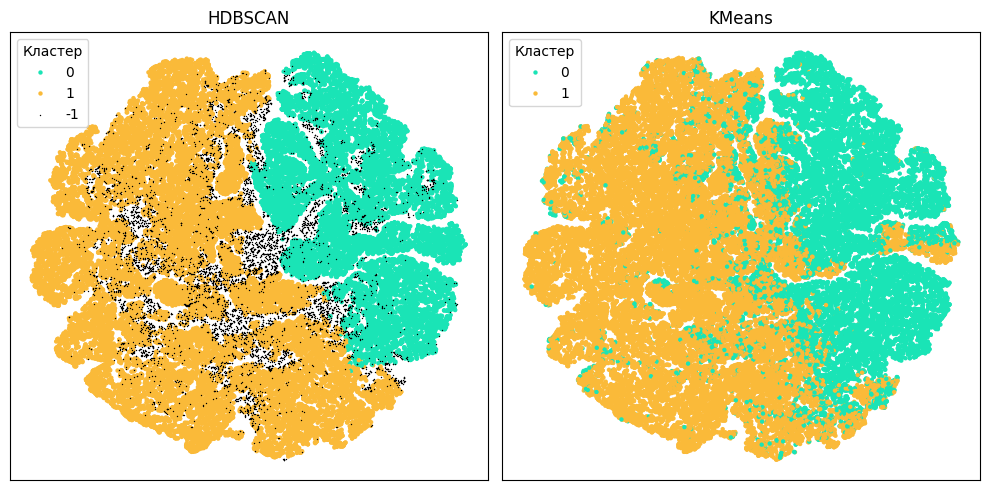

In [72]:
vwc.show_2d_spaces(
    efficientnet_visual2_tsne_l2, 
    'cluster_hdbscan', 'cluster_kmeans_aligned',
    frac=0.1, palette='turbo'
)

### UMAP/HDBSCAN на 5 кластеров

In [86]:
# Уменьшим cluster_selection_epsilon и min_cluster_size

umap_n_neighbors = 50
umap_dim = 5
eps_value = 0.1
min_samples_value = 50 

# Коэффициент увеличения объема выборки
scale = 1.0 / calibration_factor

# UMAP: n_neighbors масштабируется через логарифм
n_neighbors_full = int(umap_n_neighbors * (1.0 + np.log2(scale)))

# 2. HDBSCAN: min_samples задает радиус ядерных точек (core distance). 
# Если плотность в выборке вырастает, то радиус должен уменьшиться.
min_samples_full = int(min_samples_value * (1.0 + np.log2(scale)))

# 3. HDBSCAN: epsilon сжимается обратно пропорционально линейной плотности в d-мерном пространстве UMAP
eps_full = eps_value * (calibration_factor ** (1.0 / umap_dim))

# 4. HDBSCAN: min_cluster_size необходимо сохранить в размере 2% данных, так как модель склонна создавать много маленьких кластеров
min_cluster_size_full = max(1, int(X_trans.shape[0] * 0.02)) 

print(f'{scale=}, n_neighbors={n_neighbors_full}, min_samples={min_samples_full}, cluster_selection_epsilon={eps_full:.2f}, min_cluster_size={min_cluster_size_full}')

hdb_grain = hdbscan.HDBSCAN(
    min_cluster_size=min_cluster_size_full, 
    min_samples=min_samples_full,     
    cluster_selection_epsilon=eps_full,
    cluster_selection_method="eom",
    core_dist_n_jobs=12,
    prediction_data=True
)
efficientnet_grain_labels_l2_hdbscan = hdb_grain.fit_predict(X_umap)

scale=4.0, n_neighbors=150, min_samples=150, cluster_selection_epsilon=0.08, min_cluster_size=8326


In [87]:
# Распределение кластеров
pd.concat([
    pd.Series(efficientnet_grain_labels_l2_hdbscan).value_counts(normalize=True),
    pd.Series(efficientnet_grain_labels_l2_hdbscan).value_counts(normalize=False)
], axis=1).sort_index()

,proportion,count
-1,0.374206,155787
0,0.291854,121503
1,0.086137,35860
2,0.073863,30750
3,0.050094,20855
4,0.123846,51559


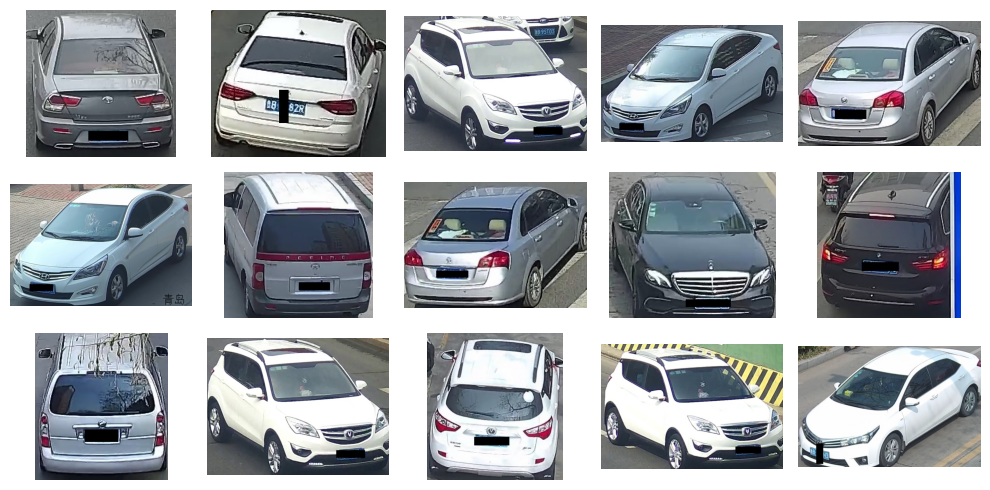

In [88]:
# 15 самых типичных представителей класса 0 в efficientnet-b7

efficientnet_0_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain, 0, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_0_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

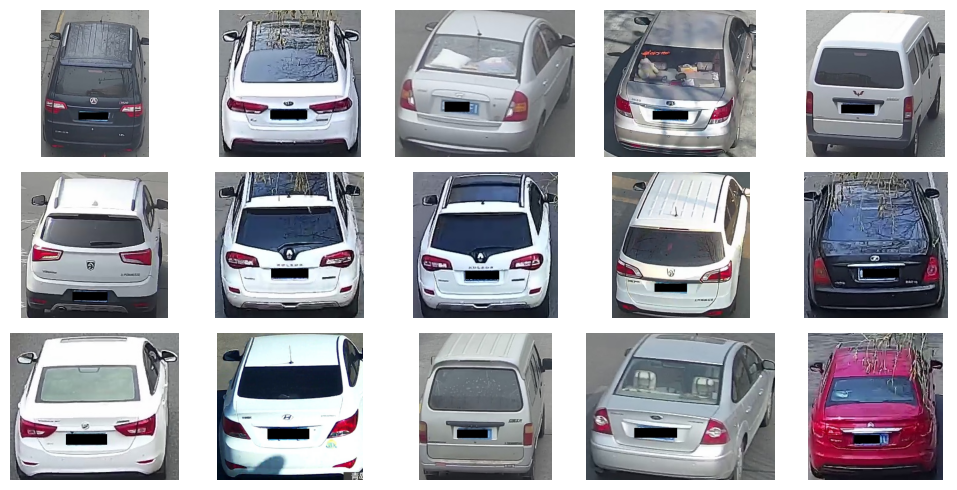

In [89]:
# 15 самых типичных представителей класса 1 в efficientnet-b7

efficientnet_1_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain, 1, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_1_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

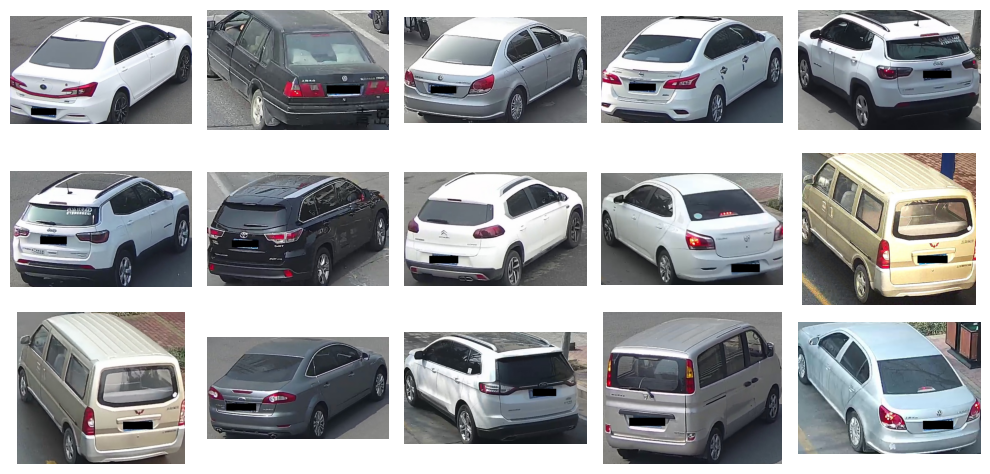

In [90]:
# 15 самых типичных представителей класса 2 в efficientnet-b7

efficientnet_2_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain, 2, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_2_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

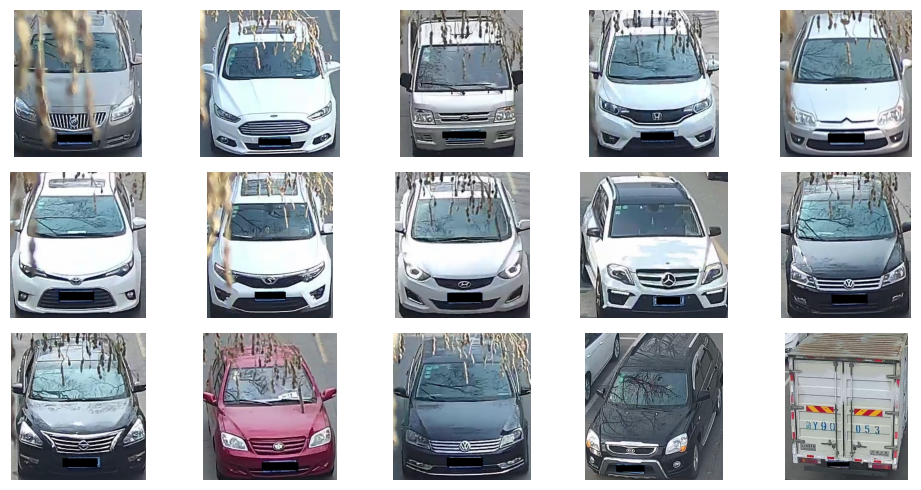

In [91]:
# 15 самых типичных представителей класса 3 в efficientnet-b7

efficientnet_3_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain, 3, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_3_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

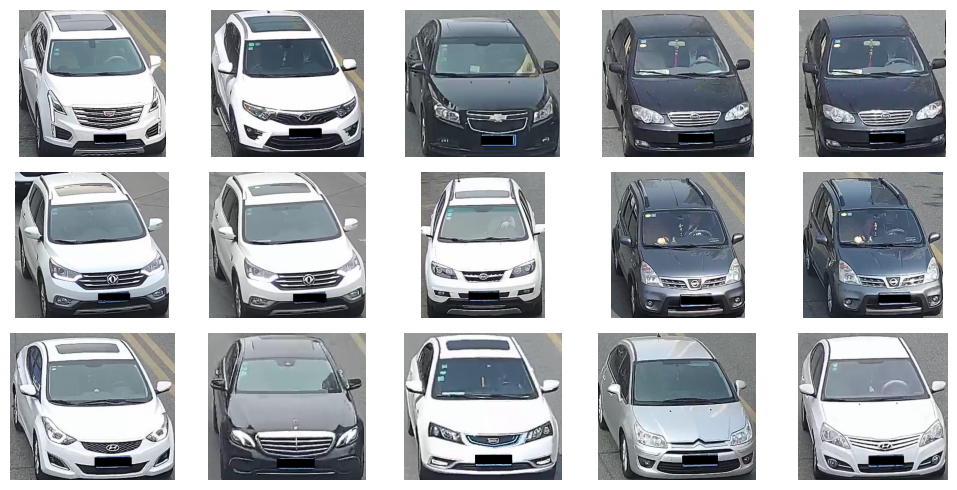

In [92]:
# 15 самых типичных представителей класса 4 в efficientnet-b7

efficientnet_4_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain, 4, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_4_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

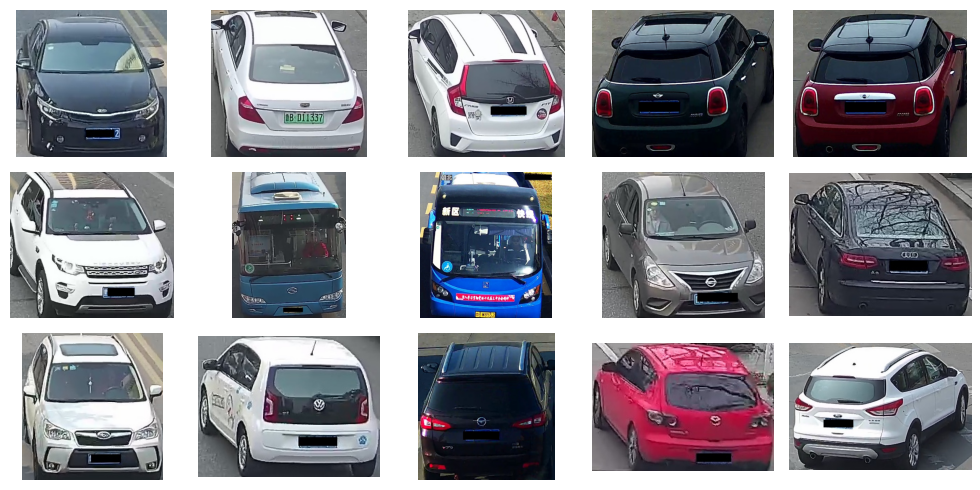

In [93]:
# 10 самых далеких выбросов в efficientnet-b7
efficientnet_hdbscan_outliers_l2 = vwc.get_hdbscan_outliers_samples(hdb_grain, 15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_hdbscan_outliers_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

In [94]:
efficientnet_grain_visual2_tsne_l2 = pd.DataFrame(
    np.hstack([
        X_tsne, 
        efficientnet_grain_labels_l2_hdbscan.reshape(-1, 1),
        efficientnet_labels_l2_kmeans.reshape(-1, 1)
    ]), 
    columns=['x', 'y', 'cluster_hdbscan', 'cluster_kmeans']
)
efficientnet_grain_visual2_tsne_l2['cluster_hdbscan'] = efficientnet_grain_visual2_tsne_l2['cluster_hdbscan'].astype(np.int8)
efficientnet_grain_visual2_tsne_l2['cluster_kmeans'] = efficientnet_grain_visual2_tsne_l2['cluster_kmeans'].astype(np.int8)

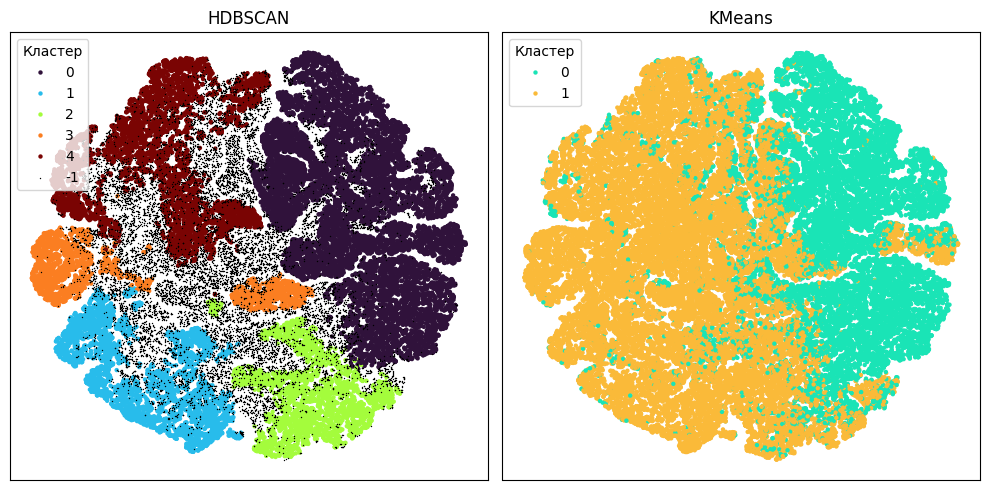

In [95]:
vwc.show_2d_spaces(
    efficientnet_grain_visual2_tsne_l2, 
    'cluster_hdbscan', 'cluster_kmeans',
    frac=0.1, palette='turbo'
)

### Мягкая кластеризация с регулировкой уровня шума

Применим "мягкий" способ назначения меток с помощью вектора вероятностей принадлежности membership_vector. Каждая строка матрицы содержит силу связи точки с каждым из найденных кластеров. В отличие от softmax сумма по строке не обязана быть равна 1.0. Если максимальная уверенность равна нулю или очень мала, например, меньше 0.05, то такие точки являются истинными выбросами (аномалиями) топологии UMAP. Таких точек в датасете нет. 

Для шума оставим фиксированную долю, например, 5%. В эту категорию попадут, соответственно, 5% точек с самыми низкими значениями уверенности.

In [96]:
# Матрица вероятностей
membership_vectors = hdbscan.all_points_membership_vectors(hdb_grain)
print(f"Размерность матрицы вероятностей: {membership_vectors.shape}")

# 1. Наиболее вероятный кластер для каждого объекта
best_clusters_grain_l2 = np.argmax(membership_vectors, axis=1)

# 2. Максимальная вероятность (сила связи с лучшим кластером).
# Каждая строка матрицы membership_vectors содержит силу связи точки с каждым из найденных кластеров. 
# В отличие от softmax, сумма по строке не обязана быть равна 1.0: точки в зонах разреженности имеют 
# околонулевые значения во всех столбцах.
max_probs = np.max(membership_vectors, axis=1)
print('Минимальная сила связи:', np.min(max_probs))
print()

# Перцентили распределения максимальных вероятностей (распределение уверенности)
percentiles = [1, 5, 10, 15, 20, 25, 50, 75, 90]
df_pct = pd.DataFrame(
    {"Percentile": percentiles, "Max_Probability": np.percentile(max_probs, percentiles)}
)
print(df_pct.to_string(index=False))

Размерность матрицы вероятностей: (416314, 5)
Минимальная сила связи: 0.041224178983023385

 Percentile  Max_Probability
          1         0.114314
          5         0.153052
         10         0.187953
         15         0.212181
         20         0.235921
         25         0.263212
         50         0.476710
         75         0.876932
         90         1.000000


In [97]:
# 3. Фиксируем желаемую долю шума (например, 5%)
target_noise_pct = 5.0
threshold_prob = np.percentile(max_probs, target_noise_pct)

print(f"Порог отсечения для {target_noise_pct}% шума: {threshold_prob:.4f}")
print()

# 4. Формируем итоговые метки:
# Если уверенность ниже порога -> шум (-1), иначе -> лучший кластер
efficientnet_grain_labels_l2 = np.where(max_probs >= threshold_prob, best_clusters_grain_l2, -1)

# 5. Проверка распределения меток
res_series = pd.Series(efficientnet_grain_labels_l2)
print("Итоговое распределение кластеров:")
print(
    pd.concat(
        [res_series.value_counts(normalize=True), res_series.value_counts()],
        axis=1,
        keys=["proportion", "count"],
    ).sort_index()
)

Порог отсечения для 5.0% шума: 0.1531

Итоговое распределение кластеров:
    proportion   count
-1    0.050001   20816
 0    0.334272  139162
 1    0.198946   82824
 2    0.142431   59296
 3    0.076726   31942
 4    0.197625   82274


In [109]:
# Класс-костыль для поиска лучших представителей кластеров и выбросов
class pseudomodel:
    def __init__(self, labels, probabilities):
        self.labels_ = labels
        self.probabilities_ = probabilities
        self.outlier_scores_ = -probabilities
        
hdb_grain_pm = pseudomodel(efficientnet_grain_labels_l2, max_probs)

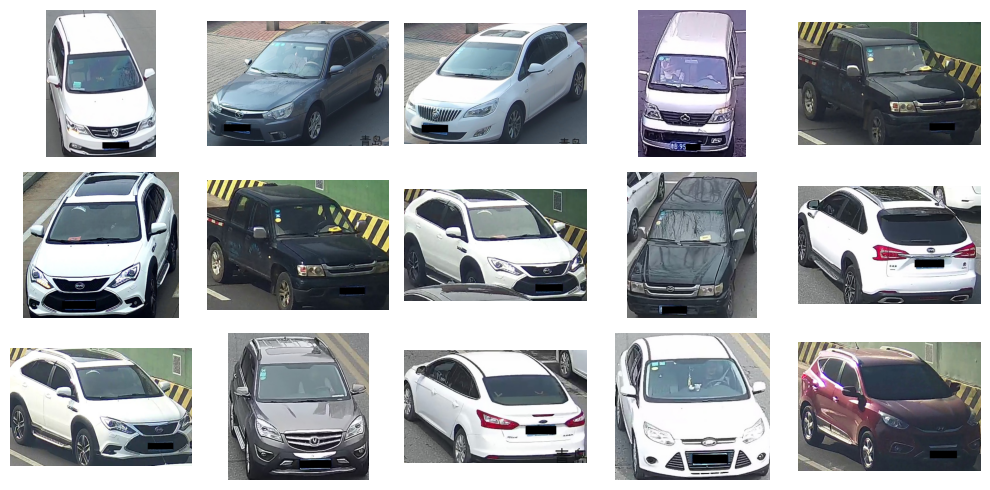

In [110]:
# 15 самых типичных представителей класса 0 в efficientnet-b7
efficientnet_grain0_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain_pm, 0, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_grain0_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

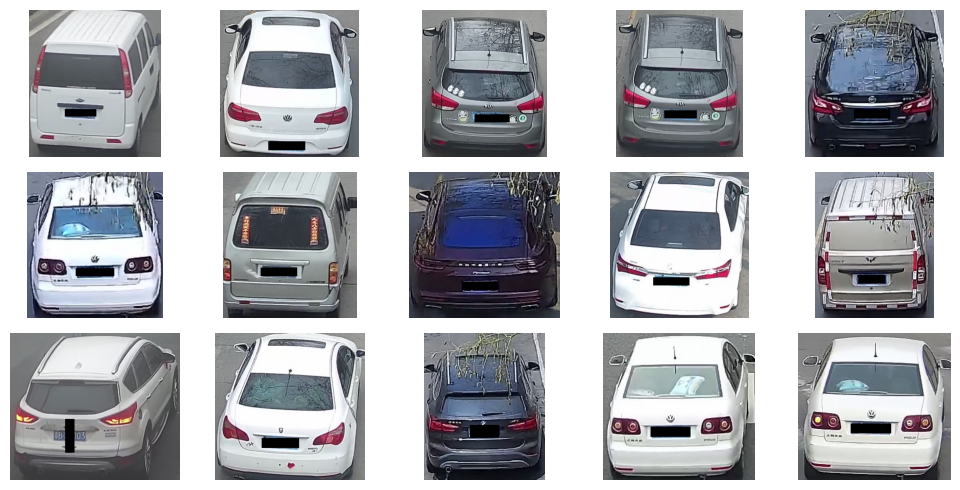

In [111]:
# 15 самых типичных представителей класса 1 в efficientnet-b7
efficientnet_grain1_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain_pm, 1, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_grain1_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

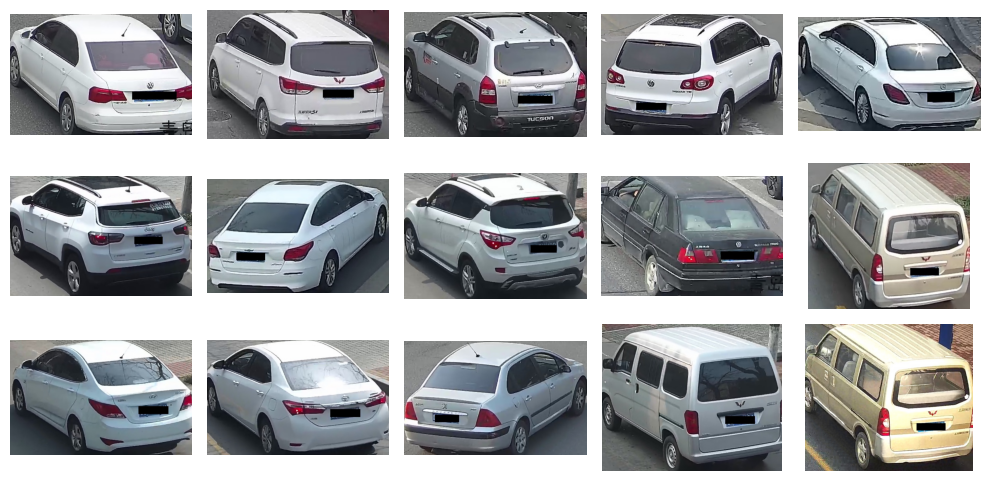

In [112]:
# 15 самых типичных представителей класса 2 в efficientnet-b7
efficientnet_grain2_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain_pm, 2, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_grain2_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

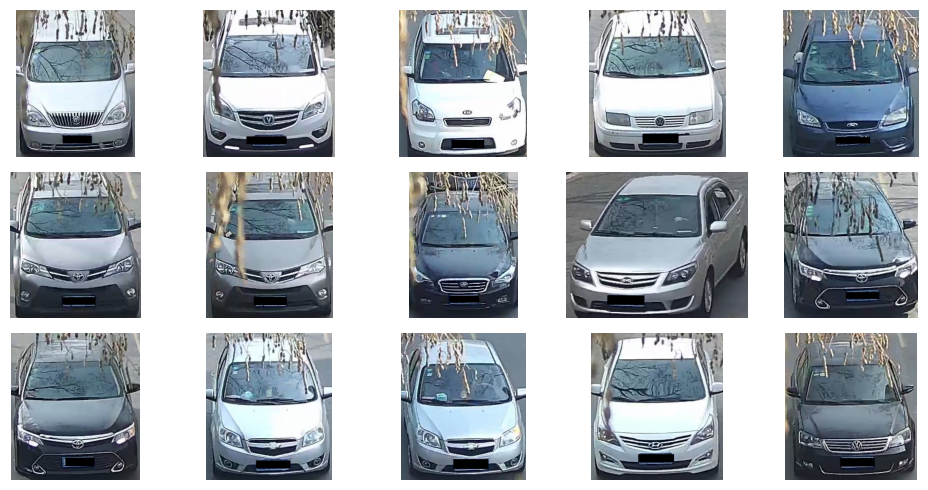

In [113]:
# 15 самых типичных представителей класса 3 в efficientnet-b7
efficientnet_grain3_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain_pm, 3, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_grain3_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

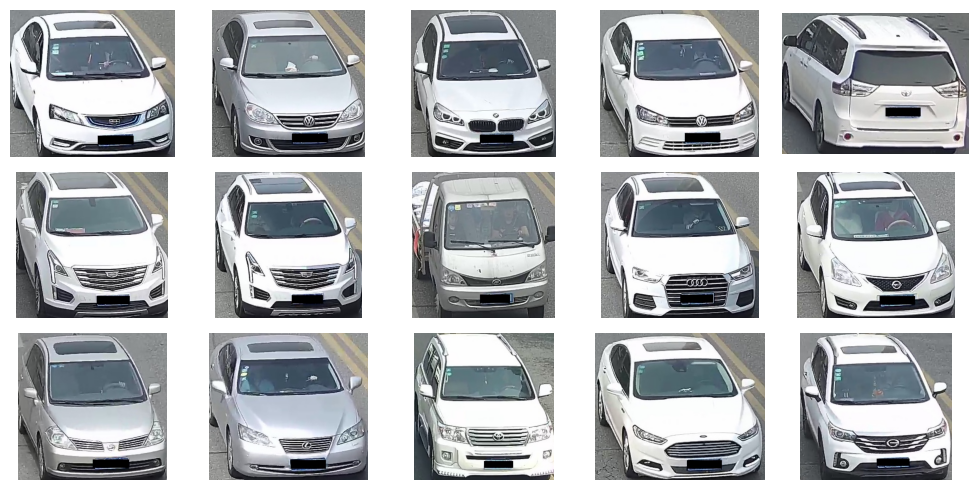

In [114]:
# 15 самых типичных представителей класса 4 в efficientnet-b7
efficientnet_grain4_indices_l2 = vwc.get_hdbscan_best_cluster_samples(hdb_grain_pm, 4, n_samples=15)
vwc.draw_images(
    imgpath,
    imglist[efficientnet_grain4_indices_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

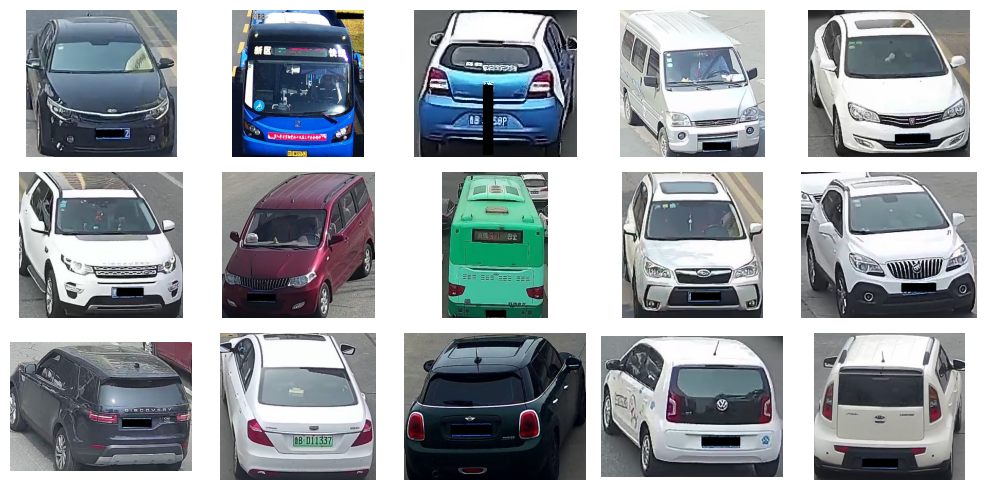

In [115]:
# 15 самых далеких выбросов в efficientnet-b7

# Маска выбросов (метка -1)
outlier_mask = (efficientnet_grain_labels_l2 == -1)
    
# Индексы всех выбросов в исходном массиве
outlier_indices = np.where(outlier_mask)[0]

# Scores только для выбросов
outlier_subset_prob = max_probs[outlier_mask]

# Самые сильные выбросы (15 наименьших значений)
kout = min(15, len(outlier_subset_prob))
bottom_kout_local_idx = np.argsort(outlier_subset_prob)[:kout]
efficientnet_grain_hdbscan_outliers_l2 = outlier_indices[bottom_kout_local_idx]

vwc.draw_images(
    imgpath,
    imglist[efficientnet_grain_hdbscan_outliers_l2].to_list(), 
    nrows=3, ncols=5, figsize=FIGSIZE_IMG2X5
)

In [106]:
efficientnet_grain_visual2_tsne = pd.DataFrame(
    np.hstack([
        X_tsne, 
        efficientnet_grain_labels_l2.reshape(-1, 1),
        efficientnet_labels_l2_kmeans.reshape(-1, 1)
    ]), 
    columns=['x', 'y', 'cluster_hdbscan', 'cluster_kmeans']
)
efficientnet_grain_visual2_tsne['cluster_hdbscan'] = efficientnet_grain_visual2_tsne['cluster_hdbscan'].astype(np.int8)
efficientnet_grain_visual2_tsne['cluster_kmeans'] = efficientnet_grain_visual2_tsne['cluster_kmeans'].astype(np.int8)

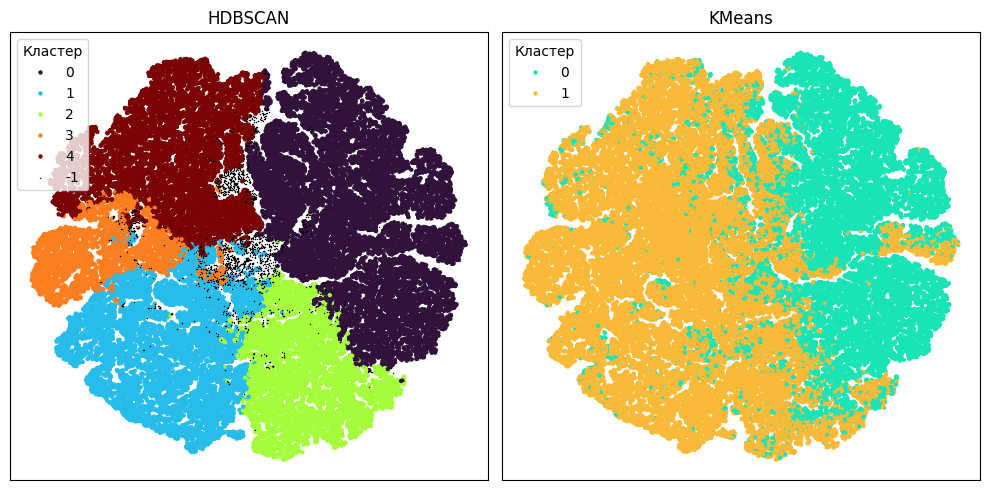

In [107]:
vwc.show_2d_spaces(
    efficientnet_grain_visual2_tsne, 
    'cluster_hdbscan', 'cluster_kmeans',
    frac=0.1, palette='turbo'
)

Получили подтверждение, что нормализация по строкам действительно помогает получить осмысленные кластеры и что принципом группировки является ракурс съемки — угол автомобиля по отношению к направлению камеры и вид спереди/сзади. Предположительно, в кластере 0 собралиь изображения с посторонними предметами, элементами дорожной разметки и т.п. Важно отметить его сходство с кластером 0, который предложил алгоритм KMeans. Близкие ветви деревьев, закрывающие автомобиль с фронта, собрались в кластере 3, самом немногочисленном (7% данных), хотя на одной картинке есть лишь отражения ветвей на лобовом стекле, но не сами ветви.

In [ ]:
# Сохранение меток
efficientnet_grain_visual2_tsne[['cluster_hdbscan', 'cluster_kmeans']].to_csv(
    os.path.join('temp', 'efficientnet_rowspipeline_labels.csv'), 
    index=False
)